In [182]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [183]:
from pygraphon.graphons.StepGraphon import StepGraphon
import numpy as np
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt
from pygraphon.utils.utils_graph import edge_density
from tqdm import tqdm

In [184]:
#Set the matrix of theta
graphon_matrix = np.array([[0.8,0.1,0.1],[0.1,0.8,0.1],[0.1,0.1,0.8]])
#set up normalised graphon with graphon
graphon = StepGraphon(graphon_matrix,1/3)

In [185]:
from pygraphon.graphons import graphon_log

In [186]:
#original integral and normalised one
print(graphon.integral(graphon_matrix), graphon.integral())

0.33333333333333337 1.0


In [187]:
#new graphon after normalisation
graphon.graphon

array([[2.4, 0.3, 0.3],
       [0.3, 2.4, 0.3],
       [0.3, 0.3, 2.4]])

In [188]:
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt

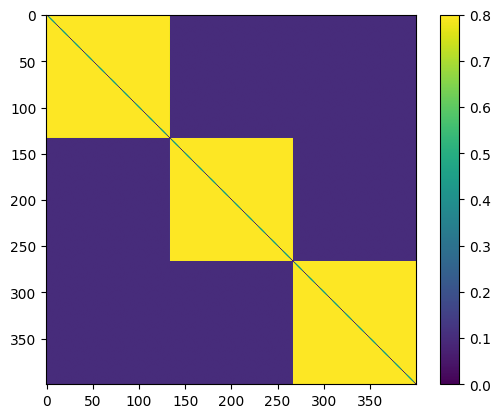

In [189]:
plt.imshow(graphon._get_edge_probabilities(400,False,True))
plt.colorbar()
plt.show()

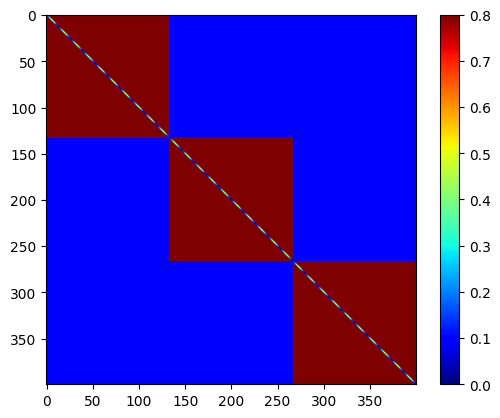

In [211]:
#Draw a graph from the graphon with a given density and number of vertices, see GraphonAbstract.py
from pygraphon.graphons import graphon_logit_sum
A = graphon.draw(rho = 1,n = 300, exchangeable=False)
plt.imshow(graphon._get_edge_probabilities(400,False,True), cmap = "jet")
plt.colorbar()
plt.show()

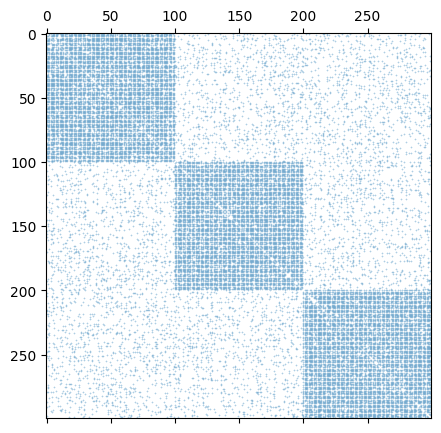

In [212]:
fig, ax = spy(A)#from pygraphon.plots.plot_matrices
plt.show()

In [213]:
edge_density(A)

0.33181716833890745

In [214]:
from pygraphon.estimators import HistogramEstimator, MomentEstimator, SimpleMomentEstimator

In [215]:
hist = HistogramEstimator()
hist.fit(graph= A, bandwidthHist= 1/3, method = "matlab")

Initial log-likelihood: -22688.403777738604
fast normalized ll: -0.5058729939295118
Initial normalized log-likelihood: -1.5245534053043008


LL: -0.4305,  0 global improvements:   4%|▍         | 20/500 [00:14<05:50,  1.37it/s]

3 consecutive likelihood improvements less than specified tolerance; quitting now
Best LL: -0.4305


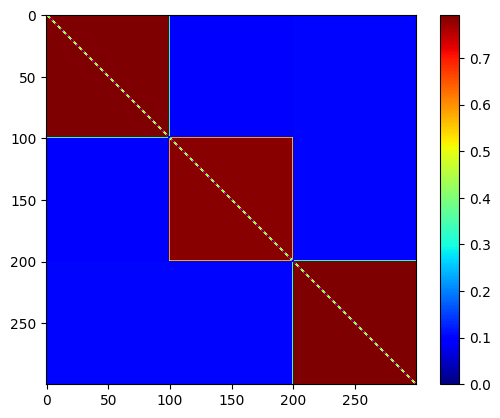

In [221]:
plt.imshow(hist.get_graphon()._get_edge_probabilities(300,False,True), cmap = "jet")
plt.colorbar()

In [217]:
from pygraphon.norm import MseProbaEdge
norm = MseProbaEdge(n_nodes = 500)
norm(graphon, hist)

3.898120808492019e-05

In [273]:
my_hist = HistogramEstimator()
my_hist.fit(graph= A, bandwidthHist= 1/3)

Likelihood: -0.3879:   2%|▏         | 8/500 [00:28<28:42,  3.50s/it]                


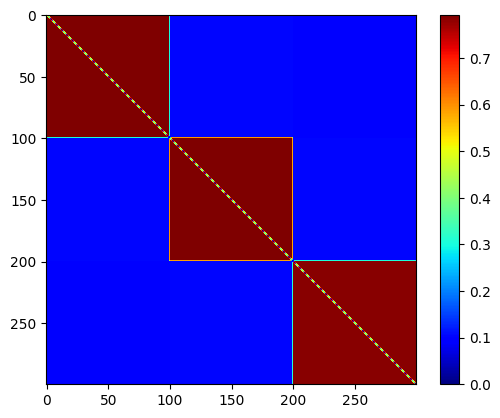

In [274]:
plt.imshow(my_hist.get_graphon()._get_edge_probabilities(300,False,True), cmap = "jet")
plt.colorbar()

In [256]:
from pygraphon.estimators.networkhistogram.greedy_readable import Assignment, update_realized_number

labels = np.load("labels.npy")
assignment_swap = Assignment(np.copy(labels),A)
swap = (51, 57)
labels[swap[0]], labels[swap[1]] = labels[swap[1]], labels[swap[0]]
assignment = Assignment(labels,A)

In [261]:
swap[0],assignment_swap.labels[swap[0]], swap[1], assignment_swap.labels[swap[1]],

(51, 1, 57, 2)

In [258]:
A[swap[0],:].nonzero()[0]

array([  1,   2,   3,   4,   5,   6,   9,  11,  12,  14,  15,  16,  17,
        18,  19,  20,  21,  22,  24,  25,  26,  27,  28,  30,  32,  33,
        34,  35,  36,  37,  38,  39,  42,  43,  45,  46,  47,  48,  49,
        50,  52,  53,  54,  55,  56,  57,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  69,  70,  71,  72,  73,  74,  75,  76,  77,  81,
        82,  84,  85,  86,  87,  88,  89,  90,  91,  93,  94,  95,  96,
        97,  98,  99, 118, 124, 129, 142, 143, 148, 201, 205, 206, 216,
       230, 240, 253, 274, 281, 287, 288, 289])

In [259]:
A[swap[1],:].nonzero()[0]

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  20,  21,  22,  23,  25,  26,  28,  29,
        30,  32,  33,  34,  36,  37,  38,  39,  41,  42,  43,  45,  46,
        47,  48,  49,  50,  51,  54,  55,  59,  60,  61,  62,  63,  64,
        67,  68,  69,  70,  71,  73,  75,  77,  78,  79,  80,  81,  85,
        86,  87,  88,  89,  90,  91,  92,  93,  94,  95,  96,  98,  99,
       100, 114, 122, 125, 129, 131, 134, 135, 140, 149, 150, 163, 169,
       171, 172, 175, 176, 188, 197, 201, 222, 243, 245, 248, 257, 265,
       271, 279, 282, 286, 287, 291, 298])

In [251]:
assignment_swap.realized

array([[3876., 1241.,  938.],
       [1241., 2097., 4410.],
       [ 938., 4410., 2320.]])

In [248]:
update_realized_number(assignment.realized, assignment.labels, A, swap)

array([[3953., 1209.,  827.],
       [1209., 2097., 4442.],
       [ 827., 4442., 2354.]])

In [243]:
assignment.realized

array([[3876., 1241.,  938.],
       [1241., 2097., 4410.],
       [ 938., 4410., 2320.]])

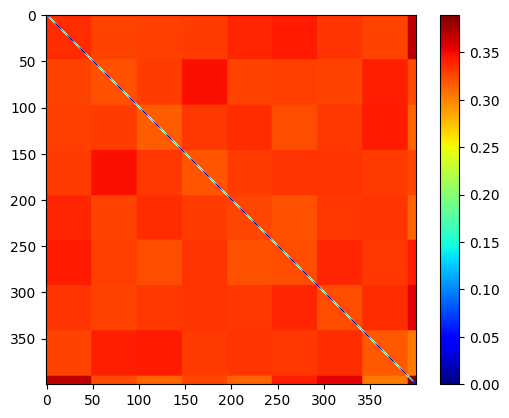

In [208]:
plt.imshow(my_hist.get_graphon()._get_edge_probabilities(400,False,True), cmap = "jet")
plt.colorbar()

In [209]:
norm(graphon, my_hist)

0.10985067657090693

In [165]:
from pygraphon.estimators.networkhistogram.nethist import nethist
best_assignment, bests, currents, overall_bests = nethist(A,int(A.shape[0]/3))

Likelihood: -0.3835: 100%|██████████| 10/10 [00:40<00:00,  4.02s/it]              


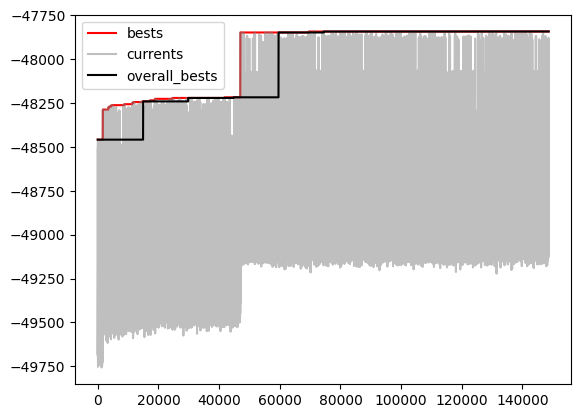

In [166]:
plt.plot(bests, label = "bests", color = "red")
plt.plot(currents, label = "currents", color = "grey", alpha = 0.5)
plt.plot(overall_bests, label = "overall_bests", color = "black")
plt.legend()
plt.show()

In [144]:
int(A.shape[0]/3)

166

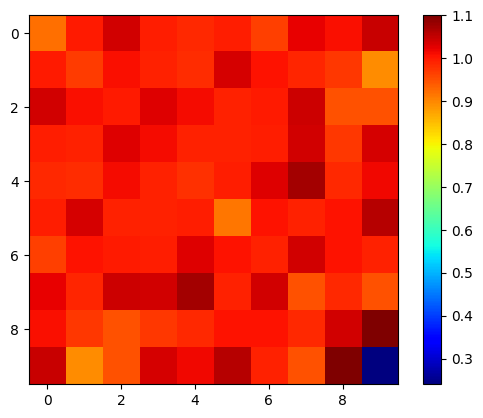

In [145]:
plt.imshow(my_hist.get_graphon().graphon, cmap = "jet")
plt.colorbar()

In [102]:
norm(graphon_logit_sum, my_hist)

0.012605417403579117

In [105]:
hist_full = HistogramEstimator()
hist_full.fit(graph= A, bandwidthHist= None)


Initial log-likelihood: -17009.947307682723
fast normalized ll: -0.1363522830275168
Initial normalized log-likelihood: -0.14430251285393014


LL: -0.0794,  4 global improvements:  46%|████▌     | 230/500 [04:14<04:58,  1.11s/it]

3 consecutive likelihood improvements less than specified tolerance; quitting now
Best LL: -0.0794


In [109]:
norm(graphon_logit_sum, hist_full)

0.02759625555737491

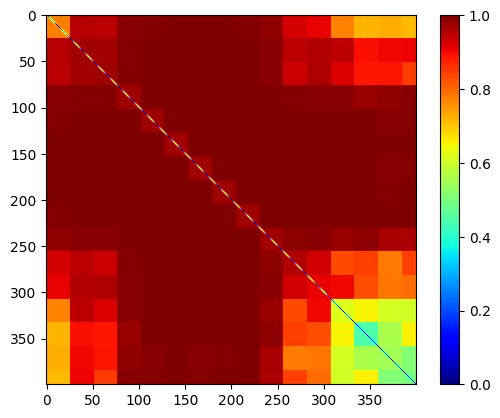

In [107]:
plt.imshow(hist_full.get_graphon()._get_edge_probabilities(400,False,True), cmap = "jet")
plt.colorbar()

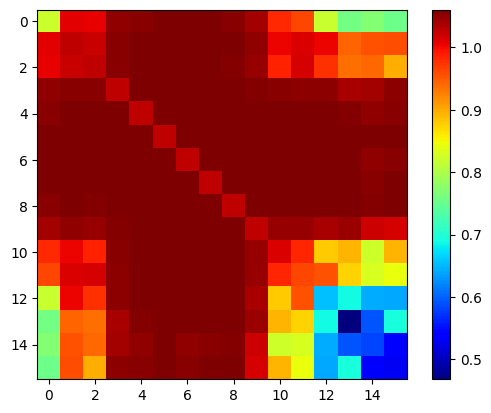

In [110]:
plt.imshow(hist_full.get_graphon().graphon, cmap = "jet")
plt.colorbar()

In [111]:
hist_full.get_graphon().graphon.shape

(16, 16)

In [176]:
from pygraphon.estimators.networkhistogram.nethist import _first_guess_blocks, _oracle_analysis_badnwidth
from pygraphon.estimators.networkhistogram.graphest_fastgreedy import graphest_fastgreedy
from pygraphon.estimators.networkhistogram.greedy_readable import greedy_opt

n = A.shape[0]
rho = edge_density(A)
n_obs = int(n*(n-1)/2)
h = int(_oracle_analysis_badnwidth(A=A.astype(float)))
starting_labels = _first_guess_blocks(A,h,rho/4)


In [178]:
best_labels, bests, currents, overalls = greedy_opt(A, starting_labels, maxNumRestarts=50)

Likelihood: -0.0000:  70%|███████   | 35/50 [00:15<00:06,  2.29it/s]                 


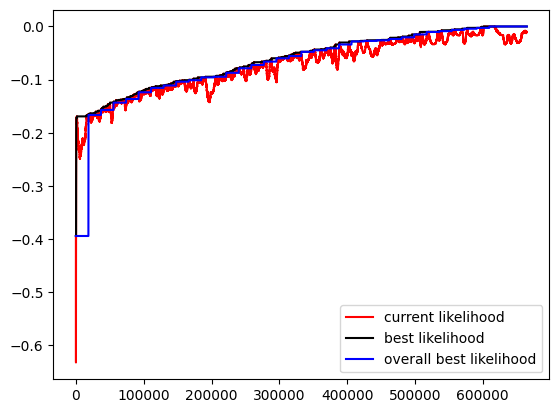

In [179]:
plt.plot(np.array(currents)/n_obs, label = "current likelihood", color = "red")
plt.plot(np.array(bests)/n_obs, label = "best likelihood", color = "black")
plt.plot(np.array(overalls)/n_obs, label = "overall best likelihood", color = "blue")
plt.legend()
plt.show()

In [ ]:
from pygraphon.estimators.networkhistogram.greedy_readable import xlogx, bernlikelihood, Assignment

In [ ]:
a = Assignment(starting_labels,A)

In [ ]:
a.likelihood

In [ ]:
best_labels, bests, currents = greedy_opt(A, starting_labels, maxNumRestarts=3)

In [ ]:
plt.plot(np.array(bests)/n_obs, label = "best likelihood", color = "red")
plt.plot(np.array(currents)/n_obs, label = "trial likelihood", color = "grey", alpha = 0.5)
plt.legend()
plt.show()

In [ ]:
a_mine = Assignment(best_labels,A)
a_matlab = Assignment(best_labels_matlab,A)

In [ ]:
print(a_mine.likelihood/n_obs, a_matlab.likelihood/n_obs)

In [ ]:
lls[-1]/n_obs

In [ ]:
lls[0]/n_obs

In [ ]:
best_labels_matlab, _, trace = graphest_fastgreedy(
            A=A, hbar=33, inputLabelVec=best_labels_matlab, verbose=True, trace=True, maxNumRestarts=10
        )
plt.plot(trace["best"], label = "best", color ="black")
plt.plot(trace["current"], label = "current", color = "red")
plt.plot(trace["trials"], label = "trials", alpha = 0.5, color ="gray")
plt.legend()
plt.show()

In [ ]:
trace["best"][-1]

In [ ]:
best_labels_matlab, _, trace = graphest_fastgreedy(
            A=A, hbar=33, inputLabelVec=best_labels_matlab, verbose=True, trace=True, maxNumRestarts=10
        )
starting_labels = best_labels_matlab
plt.plot(trace["best"], label = "best", color ="black")
plt.plot(trace["current"], label = "current", color = "red")
plt.plot(trace["trials"], label = "trials", alpha = 0.5, color ="gray")
plt.legend()
plt.show()

In [ ]:
trace["best"][0]

In [ ]:
from pygraphon.plots.plots_graphon import plot
plt.imshow(hist.get_edge_connectivity(), cmap="jet")
plt.colorbar()
plt.show()

In [ ]:
np.linalg.norm(hist.get_edge_connectivity() - P)**2/(500**2)

In [ ]:
plt.imshow(hist.get_graphon()._get_edge_probabilities(400,exchangeable = False), cmap = "jet")
plt.colorbar()

In [ ]:
from pygraphon.subgraph_isomorphism.CycleCount import CycleCount
counter = CycleCount(L = 9)

In [ ]:
momentestimator = SimpleMomentEstimator(3)
mome_simple_approx = momentestimator.estimate(adjacency_matrix= A)

In [ ]:
plot(mome_simple_approx)
plt.show()

In [ ]:
mome_simple_approx.graphon

In [ ]:
mome_simple_approx.integral()

Clustering the tiles independently (i.e. without structure)

In [ ]:
from sklearn.cluster import KMeans
#Extract tiles and reshape
nrow_tile = hist_epprox.graphon.shape[0]
flat_graphon = hist_epprox.graphon[np.triu_indices(nrow_tile)]
#Clustering according to kmeans
max_k = int(nrow_tile*(nrow_tile+1)/2)#number of individual tile
avr_graphon = [flat_graphon.copy() for k in range(max_k)]#copies for different number of clusters
for i in range(max_k-1):
    if i==0:
        avr_graphon[i]=edge_density(A)*np.ones_like(flat_graphon)
    else:
        kmeans = KMeans(n_clusters=i+1, random_state=0).fit(flat_graphon.reshape(-1,1))
        #Smooth using mean by memberhsip
        for j in range(i+1):
            avr_graphon[i][kmeans.labels_==j] = flat_graphon[kmeans.labels_==j].mean()